**Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import joblib
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

**Load Dataset**

In [ ]:
df = pd.read_csv('/content/creditcard.csv')

In [ ]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

**Defining Features and Target**

In [ ]:
X = df.drop('Class', axis=1)
y = df['Class']


In [ ]:
print(df['Class'].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


**Train Test Split for model evaluation**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**Feature Scaling**

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Applying RandomForest Algorithm**

In [ ]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train,y_train)

RandomForestClassifier(random_state=42)

**Model Prediction**

In [ ]:
y_pred= model.predict(X_test)

**Evaluating Model Accuracy**

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print(accuracy *100,'%')

99.95611109160492 %


**Bar Plot**

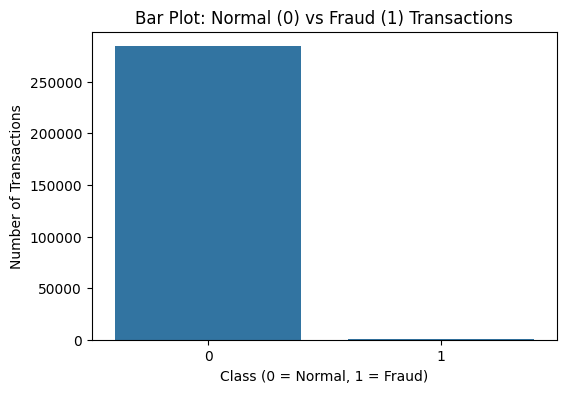

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df)
plt.title('Bar Plot: Normal (0) vs Fraud (1) Transactions')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Number of Transactions')
plt.show()

**Box Plot**

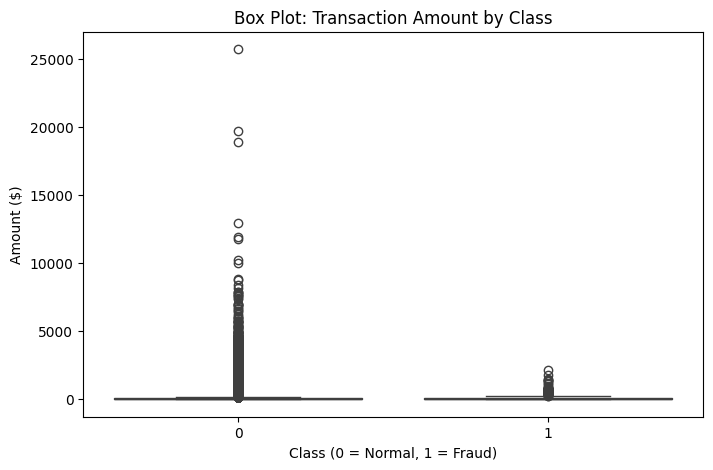

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Class', y='Amount', data=df)
plt.title('Box Plot: Transaction Amount by Class')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Amount ($)')
plt.show()

**Histogram**

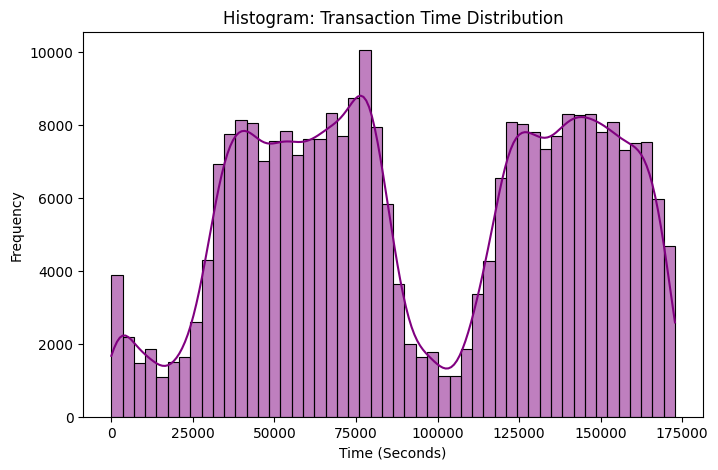

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Time'], bins=50, kde=True, color='purple')
plt.title('Histogram: Transaction Time Distribution')
plt.xlabel('Time (Seconds)')
plt.ylabel('Frequency')
plt.show()

**Scatter Plot**

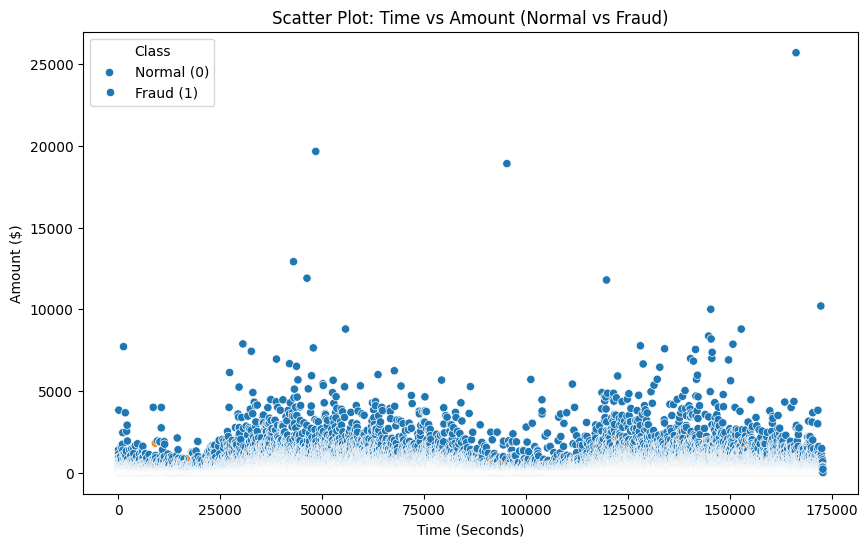

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Time', y='Amount', hue='Class', data=df)
plt.title('Scatter Plot: Time vs Amount (Normal vs Fraud)')
plt.xlabel('Time (Seconds)')
plt.ylabel('Amount ($)')
plt.legend(title='Class', labels=['Normal (0)', 'Fraud (1)'])
plt.show()

**Confusion Matrix**

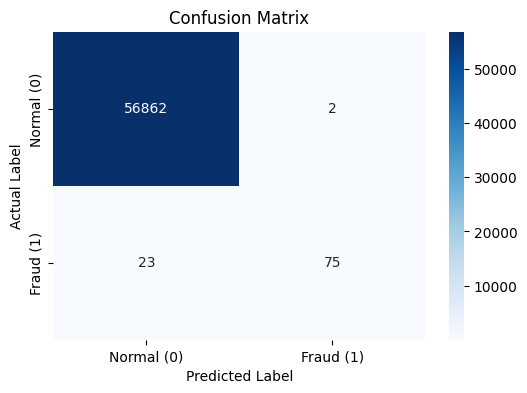

In [ ]:
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal (0)', 'Fraud (1)'],
            yticklabels=['Normal (0)', 'Fraud (1)'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

**Feature importance**

/tmp/ipykernel_1635/1644292626.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')


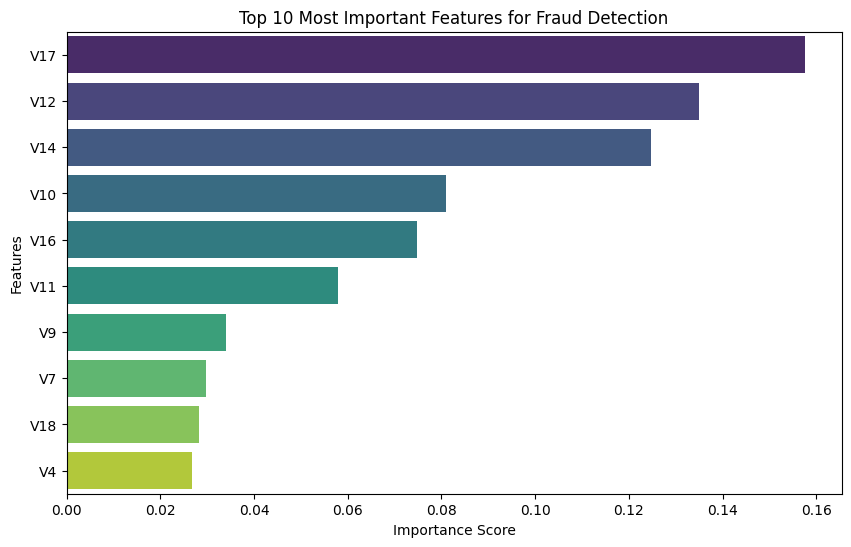

In [ ]:
feet_imp=pd.Series(model.feature_importances_,index=X.columns).sort_values(ascending=False)
feature_imp_df = feet_imp.head(10).reset_index()
feature_imp_df.columns= ['Feature','Importance']
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')
plt.title('Top 10 Most Important Features for Fraud Detection')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

**Correlation Heatmap**

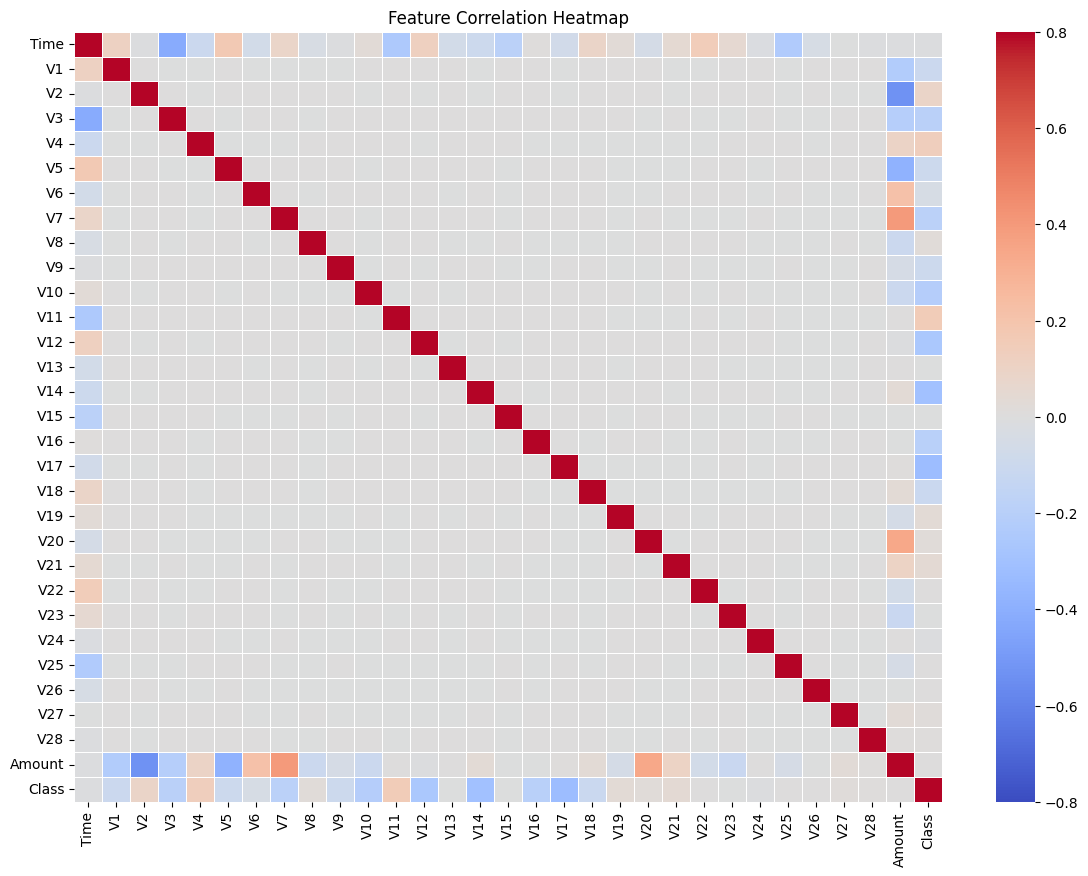

In [ ]:
plt.figure(figsize=(14, 10))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', vmax=0.8, vmin=-0.8, linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()